# Delay-duration regression: CatBoost versus a median baseline

**Question.** Among orders that are delivered late, can the 21 purchase-time predictors estimate *how many days late* more accurately than a constant guess?

This is an exploratory extension outside the report's research questions A–E. The plan, parameters and decision rule were written to `docs/machine_learning/experiment_protocol.md` (section *Extension: delay-duration regression*) before this notebook fitted any regression model. Nothing here changes the frozen classification model, calibrator, threshold or Test results.

| Item | Setting |
|---|---|
| Target | `delivery_delay_days` = actual − estimated delivery calendar date, late orders only (≥ 1 day) |
| Train | 3,720 late orders from the existing manifest |
| Validation | Validation A + B pooled: 387 + 180 = 567 late orders |
| Test | Not loaded or scored here |
| Baseline | `MedianBaseline`: the Train median delay for every order |
| Model | `CatBoostDelayRegressor`: MAE loss, 100 iterations, learning rate 0.1, depth 6, seed 42; no tuning |
| Primary metric | MAE in days, with a date-block bootstrap interval for MAE(CatBoost) − MAE(baseline) |
| Decision | CatBoost is better only if the whole 95% interval lies below 0 |

## 1. Environment and inputs

In [1]:
from pathlib import Path
from datetime import datetime
import hashlib
import importlib.metadata
import json
import platform
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

current = Path.cwd().resolve()
ROOT = next((p for p in [current, *current.parents]
             if (p / 'docs/predictor_list.csv').is_file() and (p / 'notebooks').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the project repository.')

INPUTS = ['data/processed/research_data_weather_price_holiday_assume_utc.csv',
          'docs/predictor_list.csv', 'data/ml_preparation/split_manifest.csv']
TABLES = ROOT / 'outputs/tables/delay_prediction/regression_catboost'
FIGURES = ROOT / 'outputs/figures/delay_prediction/regression_catboost'
MODELS = ROOT / 'outputs/models/delay_regression'
for path in (TABLES, FIGURES, MODELS):
    path.mkdir(parents=True, exist_ok=True)

SEED = 42
N_BOOT = 2000
DELAY_BINS = [0, 3, 7, 14, np.inf]
DELAY_LABELS = ['1–3', '4–7', '8–14', '>14']
# Late orders per split in the existing manifest; Test is deliberately absent.
EXPECTED_LATE = {'train': 3720, 'validation_a': 387, 'validation_b': 180}
COLORS = {'MedianBaseline': '#257de0', 'CatBoostDelayRegressor': '#f47230'}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.edgecolor': '#666666',
                     'axes.labelcolor': '#191919', 'xtick.color': '#666666',
                     'ytick.color': '#666666'})
run_id = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
print('Repository:', ROOT)
print('Python:', platform.python_version(), '| Run:', run_id)

Repository: C:\Users\LENOVO\OneDrive\Desktop\PTTK
Python: 3.14.6 | Run: 20261128_143719_584544


## 2. Load late orders and validate the target

Only Train, Validation A and Validation B rows are taken from the manifest. Each target is recomputed from the two delivery dates and must match `delivery_delay_days` and `is_late` exactly. Train deliveries must precede the 2018-04-16 label cutoff; validation deliveries must precede 2018-07-19.

In [2]:
features = pd.read_csv(ROOT / INPUTS[1]).feature.tolist()
assert len(features) == len(set(features)) == 21
cat = ['customer_state', 'purchase_weekday']
num = [f for f in features if f not in cat]
leak = {'delivery_delay_days', 'is_late', 'order_delivered_customer_date',
        'order_estimated_delivery_date', 'order_status'}
assert not leak & set(features), 'Outcome information must not be a predictor.'

columns = ['order_id', 'is_late', 'delivery_delay_days', 'order_delivered_customer_date',
           'order_estimated_delivery_date', *features]
source = pd.read_csv(ROOT / INPUTS[0], usecols=columns, dtype={'order_id': str})
manifest = pd.read_csv(ROOT / INPUTS[2], dtype={'order_id': str})
assert source.order_id.is_unique and manifest.order_id.is_unique

ids = manifest.loc[manifest.split.isin(EXPECTED_LATE), ['order_id', 'split', 'purchase_time']]
data = ids.merge(source, on='order_id', how='left', validate='one_to_one', indicator=True)
assert data._merge.eq('both').all()
data = data.loc[data.is_late.eq(1)].drop(columns='_merge').copy()

actual = pd.to_datetime(data.order_delivered_customer_date)
estimated = pd.to_datetime(data.order_estimated_delivery_date)
purchase = pd.to_datetime(data.purchase_time)
recomputed = (actual.dt.normalize() - estimated.dt.normalize()).dt.days
np.testing.assert_array_equal(recomputed.to_numpy(), data.delivery_delay_days.to_numpy())
assert recomputed.ge(1).all() and actual.ge(purchase).all()
cutoff = np.where(data.split.eq('train'), np.datetime64('2018-04-16'), np.datetime64('2018-07-19'))
assert (actual.to_numpy() < cutoff).all()
for split, n in EXPECTED_LATE.items():
    assert data.split.eq(split).sum() == n, split

data['y'] = data.delivery_delay_days.astype(int)
data['purchase_date'] = purchase.dt.normalize()
for c in cat:
    data[c] = data[c].map(lambda v: str(v) if pd.notna(v) else np.nan)
for c in num:
    data[c] = pd.to_numeric(data[c], errors='raise').replace([np.inf, -np.inf], np.nan)

train = data.loc[data.split.eq('train')].copy()
valid = data.loc[data.split.isin(['validation_a', 'validation_b'])].copy()
assert len(train) == 3720 and len(valid) == 567
assert not train[features].isna().all().any()
print('Train late orders:', len(train), '| Pooled validation late orders:', len(valid))

Train late orders: 3720 | Pooled validation late orders: 567


### 2.1 Delay distribution by split

Train and validation were labelled with different follow-up windows, so their delay distributions may differ. A shift here affects both models but especially a constant baseline.

In [3]:
def describe(y):
    return pd.Series({'orders': len(y), 'mean': y.mean(), 'median': y.median(),
                      'p25': y.quantile(.25), 'p75': y.quantile(.75),
                      'p90': y.quantile(.9), 'max': y.max(),
                      'share_over_14_pct': 100 * y.gt(14).mean()})

groups = {'train': train, 'validation_a': valid[valid.split.eq('validation_a')],
          'validation_b': valid[valid.split.eq('validation_b')], 'validation_pooled': valid}
data_audit = pd.DataFrame({k: describe(v.y) for k, v in groups.items()}).T
data_audit['first_purchase'] = [v.purchase_date.min().date() for v in groups.values()]
data_audit['last_purchase'] = [v.purchase_date.max().date() for v in groups.values()]
data_audit.to_csv(TABLES / 'data_audit.csv', index_label='split')
display(data_audit.round(2))

feature_audit = pd.DataFrame({'feature': features,
                              'missing_train': train[features].isna().sum().to_numpy(),
                              'missing_validation': valid[features].isna().sum().to_numpy()})
feature_audit.to_csv(TABLES / 'feature_audit.csv', index=False)
display(feature_audit.loc[feature_audit[['missing_train', 'missing_validation']].sum(axis=1) > 0])

,orders,mean,median,p25,p75,p90,max,share_over_14_pct,first_purchase,last_purchase
train,3720.0,10.74,7.0,3.0,13.0,22.0,181.0,21.83,2016-09-15,2018-03-01
validation_a,387.0,7.90,6.0,3.0,10.0,15.0,75.0,12.14,2018-04-16,2018-05-15
validation_b,180.0,5.27,4.0,2.0,7.0,10.0,20.0,2.22,2018-05-16,2018-06-01
validation_pooled,567.0,7.06,6.0,3.0,9.0,14.0,75.0,8.99,2018-04-16,2018-06-01


,feature,missing_train,missing_validation
0,distance_km_mean,25,3
11,product_category_count,73,2
15,destination_rain_state_mean_mm,46,3
16,origin_rain_state_mean_mm,5,1
17,destination_humidity_state_mean_pct,31,4
18,origin_humidity_state_mean_pct,4,0
19,destination_air_temp_state_mean_c,24,3
20,origin_air_temp_state_mean_c,3,0


## 3. Save the plan and provenance before fitting

In [4]:
regressor = CatBoostRegressor(
    loss_function='MAE', eval_metric='MAE', iterations=100, learning_rate=0.1, depth=6,
    random_seed=SEED, thread_count=4, task_type='CPU', use_best_model=False,
    allow_writing_files=False, verbose=False, cat_features=cat,
)
baseline_value = float(train.y.median())

hashes = {p: hashlib.sha256((ROOT / p).read_bytes()).hexdigest() for p in INPUTS}
lf_hashes = {p: hashlib.sha256((ROOT / p).read_bytes().replace(b'\r\n', b'\n')).hexdigest()
             for p in INPUTS}
versions = {n: importlib.metadata.version(n) for n in
            ['numpy', 'pandas', 'scikit-learn', 'joblib', 'matplotlib', 'catboost']}
versions['python'] = platform.python_version()
plan = {
    'run_id': run_id,
    'question': 'Days late among late orders: CatBoost versus Train-median baseline',
    'protocol': 'docs/machine_learning/experiment_protocol.md#extension-delay-duration-regression-declared-2026-11-28',
    'target': 'delivery_delay_days (late orders only, >= 1)',
    'fit_split': 'train (late orders)', 'score_split': 'validation_a + validation_b pooled (late orders)',
    'test_scored': False, 'tuning': False, 'early_stopping': False,
    'features': features, 'categorical_features': cat,
    'preprocessing': 'Train median for numeric features; __MISSING__ token for categories; fitted on Train late orders',
    'baseline': {'model': 'MedianBaseline', 'value_days': baseline_value},
    'CatBoostDelayRegressor': regressor.get_params(),
    'prediction_floor_days': 1, 'rounding': False,
    'primary_metric': 'MAE', 'bootstrap': {'unit': 'purchase date', 'replicates': N_BOOT,
                                           'seed': SEED, 'interval': 'percentile 95%'},
    'decision_rule': 'CatBoost better only if the full 95% interval of MAE difference is below 0',
}
(TABLES / 'experiment_plan.json').write_text(json.dumps(plan, indent=2, default=str), encoding='utf-8')
(TABLES / 'input_hashes.json').write_text(json.dumps({'raw': hashes, 'lf_normalised': lf_hashes}, indent=2), encoding='utf-8')
(TABLES / 'package_versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')
print('Baseline prediction (Train median):', baseline_value, 'days')

Baseline prediction (Train median): 7.0 days


## 4. Fit CatBoost on Train late orders

In [5]:
preprocessor = ColumnTransformer(
    [('numeric', SimpleImputer(strategy='median'), num),
     ('category', SimpleImputer(strategy='constant', fill_value='__MISSING__'), cat)],
    verbose_feature_names_out=False,
).set_output(transform='pandas')
pipeline = Pipeline([('preprocessing', preprocessor), ('regressor', regressor)])

start = time.perf_counter()
pipeline.fit(train[features], train.y)
training_seconds = time.perf_counter() - start

model_path = MODELS / 'CatBoostDelayRegressor.joblib'
joblib.dump(pipeline, model_path)
reloaded = joblib.load(model_path)
np.testing.assert_allclose(reloaded.predict(valid[features]), pipeline.predict(valid[features]))
model_sha256 = hashlib.sha256(model_path.read_bytes()).hexdigest()
print('Training seconds:', round(training_seconds, 3), '| Reload check passed')

Training seconds: 4.05 | Reload check passed


## 5. Score validation

Predictions below 1 day are raised to 1 because every evaluated order is late. The baseline uses the Train median unchanged; it is not recomputed on validation.

In [6]:
def predict(model_name, frame):
    if model_name == 'MedianBaseline':
        return np.full(len(frame), baseline_value)
    return np.maximum(pipeline.predict(frame[features]), 1.0)

MODEL_NAMES = ['MedianBaseline', 'CatBoostDelayRegressor']
for name in MODEL_NAMES:
    valid[name] = predict(name, valid)
    train[name] = predict(name, train)

def metrics(y, p):
    err = p - y
    return {'orders': len(y), 'MAE': np.abs(err).mean(), 'MedAE': np.median(np.abs(err)),
            'RMSE': np.sqrt(np.mean(err ** 2)), 'mean_error': err.mean(),
            'within_3_days_pct': 100 * (np.abs(err) <= 3).mean(),
            'prediction_mean': p.mean(), 'prediction_sd': p.std(ddof=0),
            'prediction_min': p.min(), 'prediction_max': p.max()}

rows = []
for scope, frame in [('validation_pooled', valid),
                     ('validation_a', valid[valid.split.eq('validation_a')]),
                     ('validation_b', valid[valid.split.eq('validation_b')]),
                     ('train_in_sample', train)]:
    for name in MODEL_NAMES:
        rows.append({'scope': scope, 'model': name, **metrics(frame.y.to_numpy(), frame[name].to_numpy())})
validation_metrics = pd.DataFrame(rows)
validation_metrics.to_csv(TABLES / 'validation_metrics.csv', index=False)
display(validation_metrics.round(3))

,scope,model,orders,MAE,MedAE,RMSE,mean_error,within_3_days_pct,prediction_mean,prediction_sd,prediction_min,prediction_max
0,validation_pooled,MedianBaseline,567,4.406,4.000,6.704,-0.063,47.443,7.000,0.000,7.000,7.000
1,validation_pooled,CatBoostDelayRegressor,567,4.525,3.559,6.851,-0.027,43.034,7.036,1.744,2.569,13.804
2,validation_a,MedianBaseline,387,4.822,4.000,7.600,-0.899,45.736,7.000,0.000,7.000,7.000
3,validation_a,CatBoostDelayRegressor,387,4.993,3.758,7.755,-0.672,41.344,7.227,1.744,2.569,13.804
4,validation_b,MedianBaseline,180,3.511,3.000,4.170,1.733,51.111,7.000,0.000,7.000,7.000
5,validation_b,CatBoostDelayRegressor,180,3.518,3.230,4.307,1.360,46.667,6.627,1.673,3.261,11.939
6,train_in_sample,MedianBaseline,3720,7.383,5.000,15.617,-3.736,38.978,7.000,0.000,7.000,7.000
7,train_in_sample,CatBoostDelayRegressor,3720,6.693,3.631,15.089,-3.654,43.118,7.081,1.797,1.000,31.103


## 6. Uncertainty: bootstrap of whole purchase dates

Orders bought on the same day share operating conditions, so dates rather than orders are resampled. Each replicate draws the observed number of purchase dates with replacement and recomputes the pooled MAE of both models on the same rows. The interval is a pointwise percentile interval and does not account for the period having been inspected in EDA.

In [7]:
abs_err = pd.DataFrame({n: (valid[n] - valid.y).abs() for n in MODEL_NAMES})
abs_err['purchase_date'] = valid.purchase_date.to_numpy()
by_date = abs_err.groupby('purchase_date').agg(**{n: (n, 'sum') for n in MODEL_NAMES},
                                               orders=('MedianBaseline', 'size'))
rng = np.random.default_rng(SEED)
draws = rng.integers(0, len(by_date), size=(N_BOOT, len(by_date)))
sums = {c: by_date[c].to_numpy()[draws].sum(axis=1) for c in [*MODEL_NAMES, 'orders']}
boot_mae = {n: sums[n] / sums['orders'] for n in MODEL_NAMES}
boot_diff = boot_mae['CatBoostDelayRegressor'] - boot_mae['MedianBaseline']

observed = validation_metrics.query("scope == 'validation_pooled'").set_index('model').MAE
diff = observed['CatBoostDelayRegressor'] - observed['MedianBaseline']
low, high = np.percentile(boot_diff, [2.5, 97.5])
ci = pd.DataFrame([{
    'comparison': 'CatBoostDelayRegressor minus MedianBaseline', 'metric': 'MAE (days)',
    'baseline_mae': observed['MedianBaseline'], 'catboost_mae': observed['CatBoostDelayRegressor'],
    'difference': diff, 'relative_change_pct': 100 * diff / observed['MedianBaseline'],
    'ci95_low': low, 'ci95_high': high,
    'share_of_replicates_below_0_pct': 100 * (boot_diff < 0).mean(),
    'purchase_dates': len(by_date), 'replicates': N_BOOT,
    'catboost_better': bool(high < 0),
}])
ci.to_csv(TABLES / 'mae_difference_ci.csv', index=False)
display(ci.round(4).T)

,0
comparison,CatBoostDelayRegressor minus MedianBaseline
metric,MAE (days)
baseline_mae,4.4056
catboost_mae,4.5252
difference,0.1195
relative_change_pct,2.7133
ci95_low,-0.0245
ci95_high,0.2578
share_of_replicates_below_0_pct,4.7
purchase_dates,43


## 7. Errors by actual delay group

The actual delay defines each group, so this table shows *where* each model errs; it is not something available at prediction time. A constant baseline is necessarily too high for short delays and too low for long ones.

In [8]:
valid['delay_group'] = pd.cut(valid.y, DELAY_BINS, labels=DELAY_LABELS)
group_rows = []
for group, frame in valid.groupby('delay_group', observed=True):
    for name in MODEL_NAMES:
        err = frame[name] - frame.y
        group_rows.append({'delay_group': group, 'model': name, 'orders': len(frame),
                           'actual_median': frame.y.median(), 'prediction_median': frame[name].median(),
                           'MAE': err.abs().mean(), 'mean_error': err.mean()})
delay_group_metrics = pd.DataFrame(group_rows)
delay_group_metrics.to_csv(TABLES / 'delay_group_metrics.csv', index=False)
display(delay_group_metrics.round(2))

,delay_group,model,orders,actual_median,prediction_median,MAE,mean_error
0,1–3,MedianBaseline,189,2.0,7.00,5.07,5.07
1,1–3,CatBoostDelayRegressor,189,2.0,6.82,5.00,5.00
2,4–7,MedianBaseline,182,5.0,7.00,1.49,1.49
3,4–7,CatBoostDelayRegressor,182,5.0,6.62,1.99,1.43
4,8–14,MedianBaseline,145,10.0,7.00,3.40,-3.40
5,8–14,CatBoostDelayRegressor,145,10.0,6.98,3.39,-3.13
6,>14,MedianBaseline,51,19.0,7.00,15.18,-15.18
7,>14,CatBoostDelayRegressor,51,19.0,6.91,15.06,-15.06


## 8. Descriptive diagnostics

Feature importance is CatBoost's own `PredictionValuesChange` on the fitted model. It describes how this model uses the inputs; it is not a causal effect and does not answer the report's feature-group question D.

In [9]:
importance = pd.DataFrame({'feature': features,
                           'importance': pipeline.named_steps['regressor'].get_feature_importance()})
importance = importance.sort_values('importance', ascending=False, ignore_index=True)
importance.to_csv(TABLES / 'feature_importance.csv', index=False)
display(importance.head(10).round(2))

predictions = valid[['order_id', 'split', 'purchase_date', 'y', *MODEL_NAMES, 'delay_group']].rename(
    columns={'y': 'actual_delay_days', 'MedianBaseline': 'baseline_prediction',
             'CatBoostDelayRegressor': 'catboost_prediction'})
predictions.to_csv(TABLES / 'validation_predictions.csv', index=False)

,feature,importance
0,destination_air_temp_state_mean_c,13.84
1,origin_humidity_state_mean_pct,9.51
2,origin_air_temp_state_mean_c,8.05
3,freight_value,7.59
4,destination_rain_state_mean_mm,6.23
5,purchase_weekday,6.17
6,estimated_window_days,5.88
7,distance_km_mean,5.45
8,purchase_hour,5.11
9,days_to_next_national_holiday,5.08


## 9. Figures

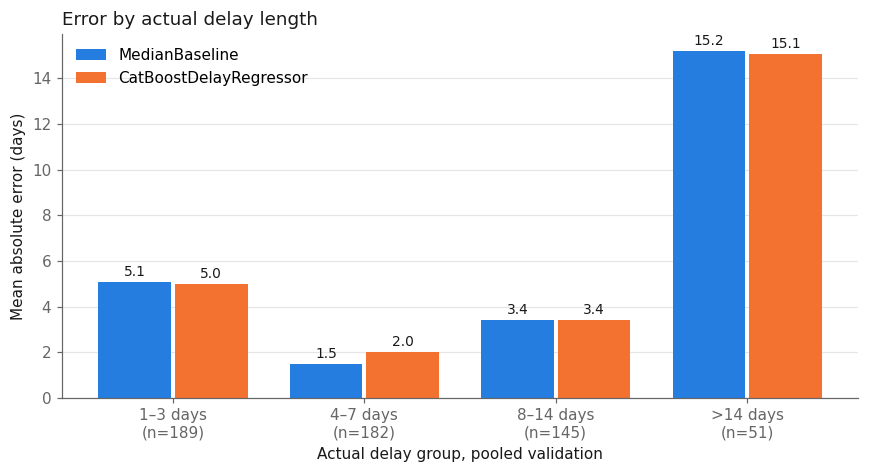

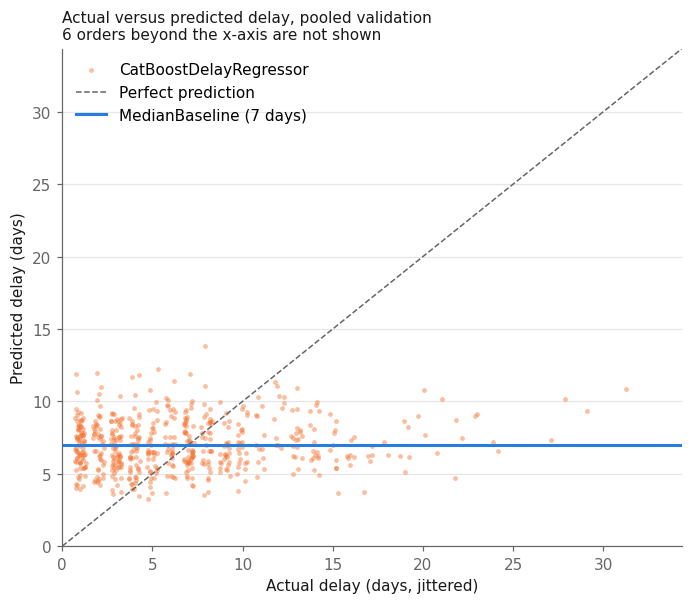

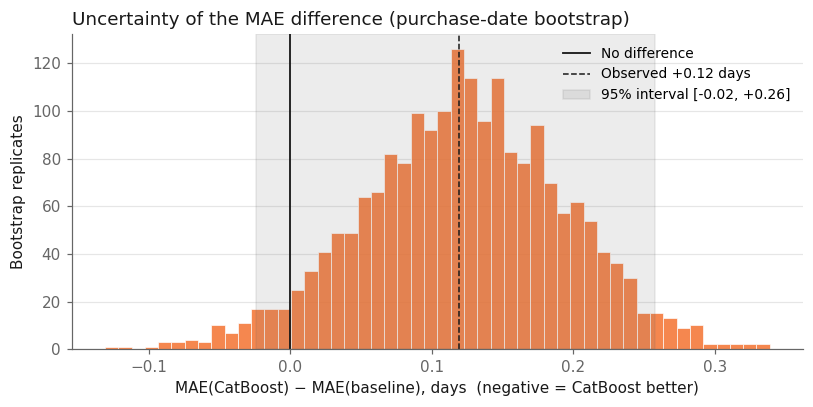

In [10]:
def style(ax):
    ax.grid(axis='y', color='#e6e6e6', linewidth=0.8)
    ax.set_axisbelow(True)

# Figure 1: MAE by actual delay group, both models side by side.
fig, ax = plt.subplots(figsize=(8, 4.4))
pivot = delay_group_metrics.pivot(index='delay_group', columns='model', values='MAE').loc[DELAY_LABELS, MODEL_NAMES]
counts = delay_group_metrics.drop_duplicates('delay_group').set_index('delay_group').orders.loc[DELAY_LABELS]
x = np.arange(len(pivot)); width = 0.38
for i, name in enumerate(MODEL_NAMES):
    bars = ax.bar(x + (i - 0.5) * (width + 0.02), pivot[name], width, color=COLORS[name], label=name)
    ax.bar_label(bars, fmt='%.1f', padding=2, fontsize=9, color='#191919')
ax.set_xticks(x, [f'{g} days\n(n={n})' for g, n in counts.items()])
ax.set_ylabel('Mean absolute error (days)')
ax.set_xlabel('Actual delay group, pooled validation')
ax.set_title('Error by actual delay length', loc='left', color='#191919')
ax.legend(frameon=False)
style(ax); fig.tight_layout()
fig.savefig(FIGURES / 'mae_by_delay_group.png', dpi=180, bbox_inches='tight')
plt.show(); plt.close(fig)

# Figure 2: actual versus CatBoost prediction (jittered actuals; integer delays overlap).
fig, ax = plt.subplots(figsize=(6.4, 5.6))
jitter = np.random.default_rng(SEED).uniform(-0.3, 0.3, len(valid))
ax.scatter(valid.y + jitter, valid.CatBoostDelayRegressor, s=10, alpha=0.45,
           color=COLORS['CatBoostDelayRegressor'], label='CatBoostDelayRegressor', linewidths=0)
lim = [0, max(valid.y.quantile(.99), valid.CatBoostDelayRegressor.max()) + 2]
ax.plot(lim, lim, color='#666666', linewidth=1, linestyle='--', label='Perfect prediction')
ax.axhline(baseline_value, color=COLORS['MedianBaseline'], linewidth=2, label=f'MedianBaseline ({baseline_value:g} days)')
ax.set_xlim(lim); ax.set_ylim(0, lim[1])
ax.set_xlabel('Actual delay (days, jittered)'); ax.set_ylabel('Predicted delay (days)')
over = int(valid.y.gt(lim[1]).sum())
ax.set_title(f'Actual versus predicted delay, pooled validation\n{over} orders beyond the x-axis are not shown',
             loc='left', color='#191919', fontsize=10)
ax.legend(frameon=False, loc='upper left')
style(ax); fig.tight_layout()
fig.savefig(FIGURES / 'actual_vs_predicted.png', dpi=180, bbox_inches='tight')
plt.show(); plt.close(fig)

# Figure 3: bootstrap distribution of the MAE difference.
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.hist(boot_diff, bins=50, color=COLORS['CatBoostDelayRegressor'], alpha=0.85, edgecolor='white', linewidth=0.5)
ax.axvline(0, color='#191919', linewidth=1.2, label='No difference')
ax.axvline(diff, color='#191919', linestyle='--', linewidth=1, label=f'Observed {diff:+.2f} days')
ax.axvspan(low, high, color='#666666', alpha=0.12, label=f'95% interval [{low:+.2f}, {high:+.2f}]')
ax.set_xlabel('MAE(CatBoost) − MAE(baseline), days  (negative = CatBoost better)')
ax.set_ylabel('Bootstrap replicates')
ax.set_title('Uncertainty of the MAE difference (purchase-date bootstrap)', loc='left', color='#191919')
ax.legend(frameon=False, fontsize=9)
style(ax); fig.tight_layout()
fig.savefig(FIGURES / 'mae_difference_bootstrap.png', dpi=180, bbox_inches='tight')
plt.show(); plt.close(fig)

## 10. Experiment record and conclusion

In [11]:
from IPython.display import Markdown
row = ci.iloc[0]
pooled = validation_metrics.query("scope == 'validation_pooled'").set_index('model')
split_mae = validation_metrics.query("scope in ['validation_a', 'validation_b']").pivot(
    index='scope', columns='model', values='MAE')
log = {
    'run_id': run_id, 'model_path': str(model_path.relative_to(ROOT)).replace('\\', '/'),
    'model_sha256': model_sha256, 'training_seconds': training_seconds,
    'train_late_orders': len(train), 'validation_late_orders': len(valid),
    'baseline_value_days': baseline_value,
    'pooled_mae': pooled.MAE.to_dict(), 'split_mae': split_mae.to_dict(orient='index'),
    'mae_difference': row.difference, 'ci95': [row.ci95_low, row.ci95_high],
    'catboost_better': row.catboost_better, 'test_scored': False,
}
(TABLES / 'experiment_log.json').write_text(json.dumps(log, indent=2, default=float), encoding='utf-8')

verdict = ('The whole interval is below 0, so the pre-declared rule finds CatBoost better than the baseline on pooled validation.'
           if row.catboost_better else
           'The interval is not entirely below 0, so the pre-declared rule does **not** demonstrate an improvement; the baseline is retained.')
display(Markdown(f'''
- Baseline MAE: **{row.baseline_mae:.2f}** days. CatBoost MAE: **{row.catboost_mae:.2f}** days.
- Difference: **{row.difference:+.2f}** days ({row.relative_change_pct:+.1f}%), 95% interval [{row.ci95_low:+.2f}, {row.ci95_high:+.2f}] from {N_BOOT:,} resamples of {row.purchase_dates} purchase dates.
- Separately: Validation A {split_mae.loc['validation_a', 'MedianBaseline']:.2f} → {split_mae.loc['validation_a', 'CatBoostDelayRegressor']:.2f}; Validation B {split_mae.loc['validation_b', 'MedianBaseline']:.2f} → {split_mae.loc['validation_b', 'CatBoostDelayRegressor']:.2f} days.
- {verdict}
'''))


- Baseline MAE: **4.41** days. CatBoost MAE: **4.53** days.
- Difference: **+0.12** days (+2.7%), 95% interval [-0.02, +0.26] from 2,000 resamples of 43 purchase dates.
- Separately: Validation A 4.82 → 4.99; Validation B 3.51 → 3.52 days.
- The interval is not entirely below 0, so the pre-declared rule does **not** demonstrate an improvement; the baseline is retained.


### How to read the result

- The model answers *"if this order is late, roughly how many days late?"*. At purchase time lateness is unknown, so it cannot be used alone as an alert; it would have to be combined with the classifier, whose Test precision was 6.42%.
- MAE is in days and is driven by long delays: a few orders late by several weeks dominate the error of both models.
- Train labels required delivery before 2018-04-16, so long delays from the last Train purchases are under-represented. Validation periods have already been inspected in EDA; results are exploratory.
- Feature importance describes this fitted model only. It does not establish causes or answer the report's feature-group question D.
- Parameters were not changed after the validation scores. Test is evaluated, if at all, once in a separate notebook with this frozen pipeline.